In [35]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, precision_score, recall_score, f1_score
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.manifold import TSNE
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
import matplotlib.pyplot as plt
import seaborn as sns 

In [9]:
RANDOM_STATE = 42

In [8]:
# Служебная функция для построения t-SNE графиков
def plot_tsne(X, y, title, filename):
    print(f"Построение t-SNE для: {title}")
    n_samples_tsne = min(len(X), 2000)
    indices = np.random.choice(len(X), n_samples_tsne, replace=False)
    
    X_tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=min(30, n_samples_tsne-1), n_iter=300).fit_transform(X[indices])
    y_tsne = y[indices]
    
    plt.figure(figsize=(10, 7))
    plt.scatter(X_tsne[y_tsne == 0, 0], X_tsne[y_tsne == 0, 1], label="Норма (Класс 0)", alpha=0.6, s=20, c='green')
    plt.scatter(X_tsne[y_tsne == 1, 0], X_tsne[y_tsne == 1, 1], label="Аномалия (Класс 1)", alpha=0.6, s=20, c='red')
    plt.xlabel("t-SNE признак 1")
    plt.ylabel("t-SNE признак 2")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    # plt.savefig(filename, dpi=300) # Раскоменти для сохранения фоток
    plt.show()

In [10]:
from pathlib import Path

candidates = [Path("data/creditcard.zip"), Path("lab3_fraud/data/creditcard.zip")]
data_path = next(path for path in candidates if path.exists())
df = pd.read_csv(data_path)
print("Всего записей:", len(df))
print("Аномалии:", df["Class"].sum())

Всего записей: 284807
Аномалии: 492


In [11]:
print(f"Количество записей: {df.shape[0]}, Количество признаков: {df.shape[1]}")

Количество записей: 284807, Количество признаков: 31


In [12]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [14]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.369007e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.500885e-15,-5.620335e-16,1.149614e-16,-2.426963e-15,...,1.596686e-16,-3.576577e-16,2.650499e-16,4.472317e-15,5.109395e-16,1.686100e-15,-3.662399e-16,-1.225457e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [15]:
print(df.isnull().sum().sum()) # Общее количество пропущенных значений

0


In [16]:
class_counts = df["Class"].value_counts()
print(class_counts)
print(f"Доля аномалий (Class=1): {class_counts[1] / df.shape[0] * 100:.4f}%")

Class
0    284315
1       492
Name: count, dtype: int64
Доля аномалий (Class=1): 0.1727%


In [17]:
print(f"Минимальное значение Time: {df['Time'].min()}, Максимальное значение Time: {df['Time'].max()}")
print(f"Продолжительность в часах: {df['Time'].max() / 3600:.2f} часов (примерно 2 дня)")

Минимальное значение Time: 0.0, Максимальное значение Time: 172792.0
Продолжительность в часах: 48.00 часов (примерно 2 дня)


In [18]:
df['Hour'] = (df['Time'] // 3600) % 24

In [19]:
df['Day_Cycle'] = df['Time'] // (3600 * 24) # 0 для первого дня, 1 для второго и т.д.

In [20]:
df_processed = df.drop(columns=['Time'])

In [21]:
print(df_processed.head())


         V1        V2        V3        V4        V5        V6        V7  \
0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9       V10  ...       V23       V24       V25       V26  \
0  0.098698  0.363787  0.090794  ... -0.110474  0.066928  0.128539 -0.189115   
1  0.085102 -0.255425 -0.166974  ...  0.101288 -0.339846  0.167170  0.125895   
2  0.247676 -1.514654  0.207643  ...  0.909412 -0.689281 -0.327642 -0.139097   
3  0.377436 -1.387024 -0.054952  ... -0.190321 -1.175575  0.647376 -0.221929   
4 -0.270533  0.817739  0.753074  ... -0.137458  0.141267 -0.206010  0.502292   

        V27       V28  Amount  Class  Hour  Day_Cycle  
0  0.133558 

In [22]:
# Подготовка данных
X_full = df_processed.drop("Class", axis=1)
y_full = df_processed["Class"]

# Масштабирование признаков
scaler_full = StandardScaler()
X_full_scaled = scaler_full.fit_transform(X_full)

# Разделение на обучающую и тестовую выборки
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full_scaled, y_full, test_size=0.3, random_state=RANDOM_STATE, stratify=y_full
) # stratify для сохранения пропорций классов

In [24]:
# Обучение модели Логистической регрессии
lr_full = LogisticRegression(solver='liblinear', random_state=RANDOM_STATE, class_weight='balanced') # class_weight для борьбы с дисбалансом
lr_full.fit(X_train_full, y_train_full)


LogisticRegression(class_weight='balanced', random_state=42, solver='liblinear')

In [25]:
# Предсказание и оценка
y_pred_full = lr_full.predict(X_test_full)

print("\n### Результаты Логистической регрессии на всём наборе данных:")
print("Матрица ошибок:")
print(confusion_matrix(y_test_full, y_pred_full))
print("\nОтчет по классификации:")
print(classification_report(y_test_full, y_pred_full, target_names=["Норма (0)", "Аномалия (1)"]))

precision_full = precision_score(y_test_full, y_pred_full)
recall_full = recall_score(y_test_full, y_pred_full)
f1_full = f1_score(y_test_full, y_pred_full)

print(f"Precision (полный датасет): {precision_full:.3f}")
print(f"Recall (полный датасет):    {recall_full:.3f}") # Важно для обнаружения мошенничества
print(f"F1-score (полный датасет):  {f1_full:.3f}")


### Результаты Логистической регрессии на всём наборе данных:
Матрица ошибок:
[[83449  1846]
 [   19   129]]

Отчет по классификации:
              precision    recall  f1-score   support

   Норма (0)       1.00      0.98      0.99     85295
Аномалия (1)       0.07      0.87      0.12       148

    accuracy                           0.98     85443
   macro avg       0.53      0.92      0.56     85443
weighted avg       1.00      0.98      0.99     85443

Precision (полный датасет): 0.065
Recall (полный датасет):    0.872
F1-score (полный датасет):  0.122


In [26]:
print(f"Всего аномалий в тестовой выборке: {sum(y_test_full)} из {len(y_test_full)}.")

Всего аномалий в тестовой выборке: 148 из 85443.


In [27]:
fraud = df_processed[df_processed["Class"] == 1]
normal = df_processed[df_processed["Class"] == 0].sample(n=1000, random_state=RANDOM_STATE)
data_subset = pd.concat([fraud, normal]).sample(frac=1, random_state=RANDOM_STATE) # Перемешиваем

X_subset = data_subset.drop("Class", axis=1)
y_subset_true = data_subset["Class"] # Истинные метки для подмножества

In [28]:
print(f"\nРазмер подмножества: {data_subset.shape[0]} записей")
print(f"Количество аномалий в подмножестве: {y_subset_true.sum()}")
print(f"Количество нормальных транзакций в подмножестве: {len(y_subset_true) - y_subset_true.sum()}")


Размер подмножества: 1492 записей
Количество аномалий в подмножестве: 492
Количество нормальных транзакций в подмножестве: 1000


In [29]:
# Масштабирование признаков подмножества
scaler_subset = StandardScaler()
X_subset_scaled = scaler_subset.fit_transform(X_subset)

# Расчет доли аномалий в подмножестве для параметра contamination/nu
contamination_actual = y_subset_true.sum() / len(y_subset_true)
print(f"Фактическая доля аномалий в подмножестве (contamination/nu): {contamination_actual:.4f}")

Фактическая доля аномалий в подмножестве (contamination/nu): 0.3298


In [30]:
# Изоляционный лес (Isolation Forest)
iso_forest = IsolationForest(n_estimators=100, contamination=contamination_actual, random_state=RANDOM_STATE)
y_pred_iso_subset = iso_forest.fit_predict(X_subset_scaled)
# Преобразование предсказаний: -1 (аномалия) -> 1, 1 (норма) -> 0
y_pred_iso_subset = np.where(y_pred_iso_subset == -1, 1, 0)


### 3.1 Изоляционный лес (Isolation Forest)


In [31]:
print(confusion_matrix(y_subset_true, y_pred_iso_subset))
print(classification_report(y_subset_true, y_pred_iso_subset, target_names=["Норма (0)", "Аномалия (1)"]))
precision_iso = precision_score(y_subset_true, y_pred_iso_subset)
recall_iso = recall_score(y_subset_true, y_pred_iso_subset)
f1_iso = f1_score(y_subset_true, y_pred_iso_subset)
print(f"Precision: {precision_iso:.3f}")
print(f"Recall:    {recall_iso:.3f}")
print(f"F1-score:  {f1_iso:.3f}")

[[886 114]
 [114 378]]
              precision    recall  f1-score   support

   Норма (0)       0.89      0.89      0.89      1000
Аномалия (1)       0.77      0.77      0.77       492

    accuracy                           0.85      1492
   macro avg       0.83      0.83      0.83      1492
weighted avg       0.85      0.85      0.85      1492

Precision: 0.768
Recall:    0.768
F1-score:  0.768


Построение t-SNE для: Изоляционный лес (t-SNE на подмножестве, предсказания)


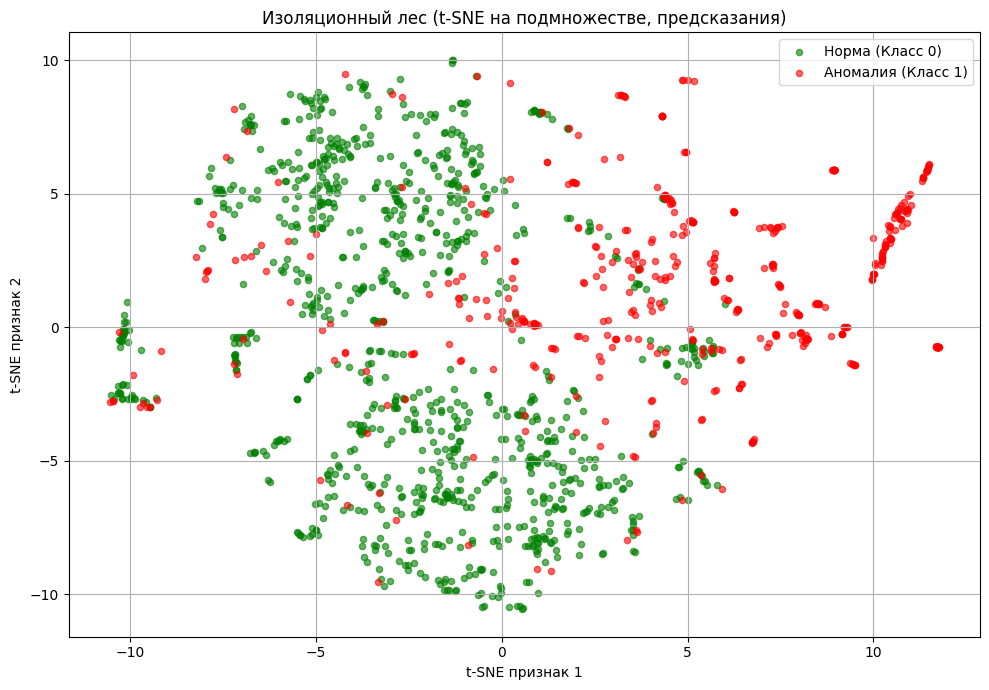

In [33]:
plot_tsne(X_subset_scaled, y_pred_iso_subset, "Изоляционный лес (t-SNE на подмножестве, предсказания)", "tsne_iso_forest_subset.png")


In [36]:
# Оклассовый метод опорных векторов (One-Class SVM)
# Параметр nu примерно соответствует доле выбросов
# One-Class SVM чувствителен к масштабированию
oc_svm = OneClassSVM(kernel='rbf', gamma='auto', nu=contamination_actual)
y_pred_ocsvm_subset = oc_svm.fit_predict(X_subset_scaled)
# Преобразование предсказаний: -1 (аномалия) -> 1, 1 (норма) -> 0
y_pred_ocsvm_subset = np.where(y_pred_ocsvm_subset == -1, 1, 0)

In [37]:
print(confusion_matrix(y_subset_true, y_pred_ocsvm_subset))
print(classification_report(y_subset_true, y_pred_ocsvm_subset, target_names=["Норма (0)", "Аномалия (1)"]))
precision_ocsvm = precision_score(y_subset_true, y_pred_ocsvm_subset)
recall_ocsvm = recall_score(y_subset_true, y_pred_ocsvm_subset)
f1_ocsvm = f1_score(y_subset_true, y_pred_ocsvm_subset)
print(f"Precision: {precision_ocsvm:.3f}")
print(f"Recall:    {recall_ocsvm:.3f}")
print(f"F1-score:  {f1_ocsvm:.3f}")

[[821 179]
 [179 313]]
              precision    recall  f1-score   support

   Норма (0)       0.82      0.82      0.82      1000
Аномалия (1)       0.64      0.64      0.64       492

    accuracy                           0.76      1492
   macro avg       0.73      0.73      0.73      1492
weighted avg       0.76      0.76      0.76      1492

Precision: 0.636
Recall:    0.636
F1-score:  0.636


In [39]:
# Автоэнкодер и Логистическая регрессия на подмножестве

# Используем X_subset_scaled и y_subset_true
# Автоэнкодер обучается ТОЛЬКО на нормальных данных из подмножества
X_subset_normal_scaled = X_subset_scaled[y_subset_true == 0]
print(f"Размер нормальных данных для обучения автоэнкодера: {X_subset_normal_scaled.shape}")

Размер нормальных данных для обучения автоэнкодера: (1000, 31)


In [42]:
input_dim = X_subset_normal_scaled.shape[1]
encoding_dim = 8 # Размерность скрытого представления

In [43]:
# Архитектура автоэнкодера
input_layer = Input(shape=(input_dim,))
# Энкодер
encoded = Dense(16, activation='relu')(input_layer)
encoded = Dense(encoding_dim, activation='relu')(encoded)
# Декодер
decoded = Dense(16, activation='relu')(encoded)
decoded = Dense(input_dim, activation='sigmoid')(decoded) # sigmoid, т.к. StandardScaler масштабирует данные обычно в диапазон, где sigmoid уместен, либо linear

autoencoder = Model(input_layer, decoded)
autoencoder.compile(optimizer='adam', loss='mse') # или 'binary_crossentropy' если данные нормализованы к [0,1]

In [44]:
autoencoder.fit(X_subset_normal_scaled, X_subset_normal_scaled,
                epochs=50,
                batch_size=32,
                shuffle=True,
                validation_split=0.2,
                verbose=1)


Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.6600 - val_loss: 0.5716
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5950 - val_loss: 0.5430
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5573 - val_loss: 0.5020
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5112 - val_loss: 0.4519
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4759 - val_loss: 0.4114
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4371 - val_loss: 0.3874
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4147 - val_loss: 0.3769
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4018 - val_loss: 0.3700
Epoch 9/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3984 - val_loss: 0.3626
Epoch 10/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3927 - val_loss: 0.3574
Epoch 11/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3745 - val_loss: 0.3533
Epoch 12/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3659 - val_l

In [45]:
# Модель энкодера для получения представлений
encoder = Model(inputs=input_layer, outputs=encoded)


Визуализация t-SNE для подмножества:
Построение t-SNE для: Подмножество до автоэнкодера (t-SNE)


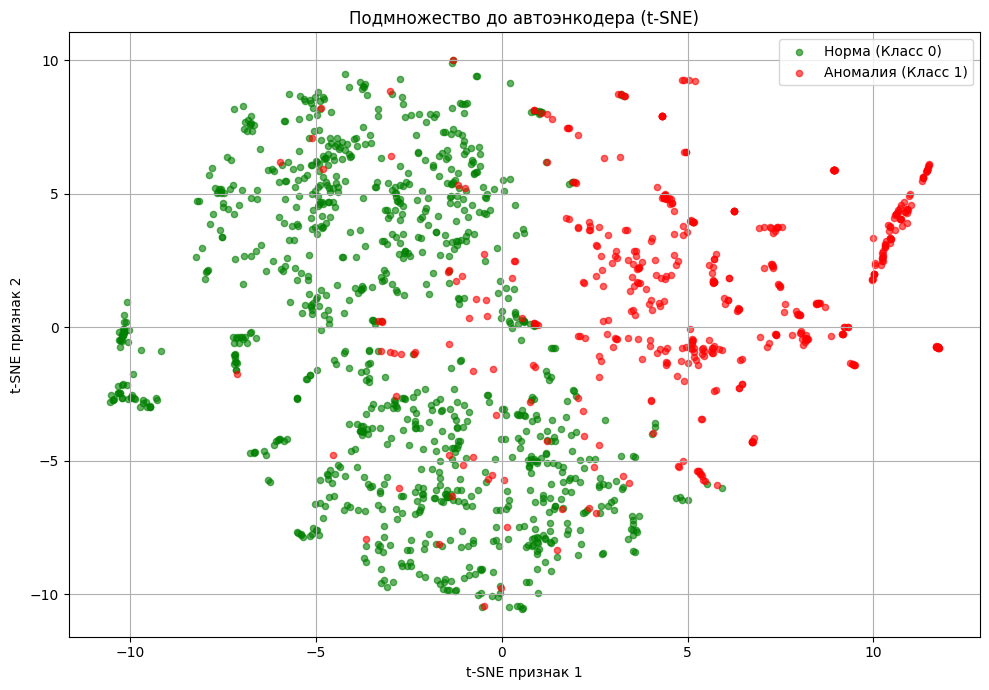

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Построение t-SNE для: Подмножество после автоэнкодера (t-SNE)


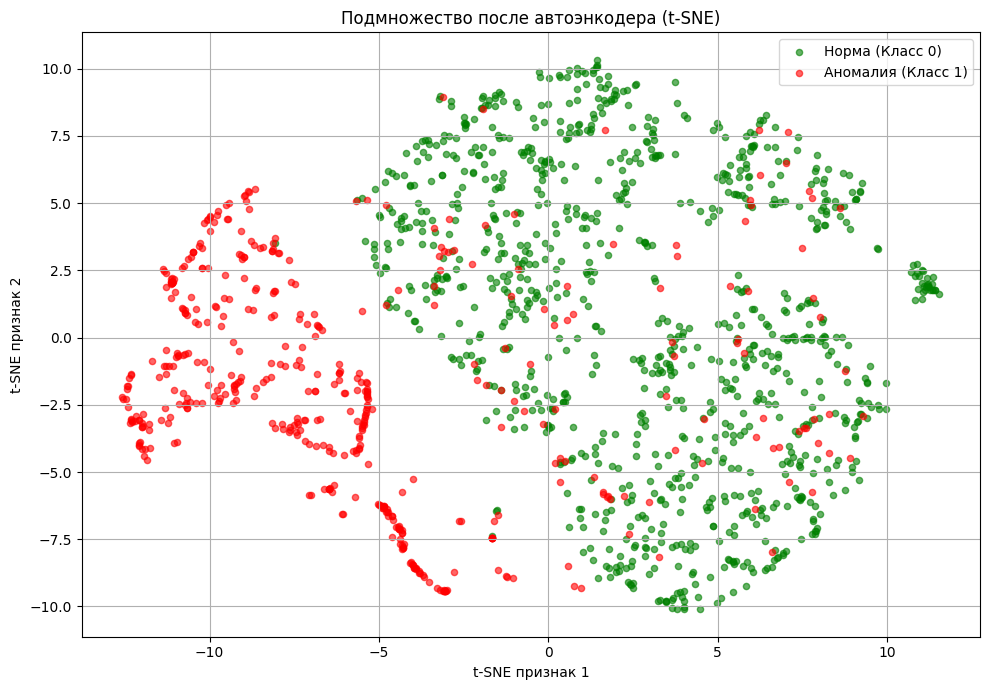

In [46]:
# Визуализация t-SNE до и после автоэнкодера (на всем подмножестве)
print("\nВизуализация t-SNE для подмножества:")
plot_tsne(X_subset_scaled, y_subset_true.to_numpy(), "Подмножество до автоэнкодера (t-SNE)", "tsne_subset_raw.png")

X_subset_encoded = encoder.predict(X_subset_scaled)
plot_tsne(X_subset_encoded, y_subset_true.to_numpy(), "Подмножество после автоэнкодера (t-SNE)", "tsne_subset_encoded.png")

In [47]:
# Классификация по представлениям с использованием логистической регрессии
X_train_enc, X_test_enc, y_train_enc, y_test_enc = train_test_split(
    X_subset_encoded, y_subset_true, test_size=0.3, random_state=RANDOM_STATE, stratify=y_subset_true
)

clf_encoded = LogisticRegression(solver='liblinear', max_iter=500, random_state=RANDOM_STATE, class_weight='balanced')
clf_encoded.fit(X_train_enc, y_train_enc)

y_pred_encoded = clf_encoded.predict(X_test_enc)


### Логистическая регрессия на данных, преобразованных автоэнкодером (подмножество)


In [48]:
# Оценка Логистической регрессии на преобразованных данных:
print("Матрица ошибок:")
print(confusion_matrix(y_test_enc, y_pred_encoded))
print(classification_report(y_test_enc, y_pred_encoded, target_names=["Норма (0)", "Аномалия (1)"]))

precision_enc = precision_score(y_test_enc, y_pred_encoded)
recall_enc = recall_score(y_test_enc, y_pred_encoded)
f1_enc = f1_score(y_test_enc, y_pred_encoded)
print(f"Precision: {precision_enc:.3f}")
print(f"Recall:    {recall_enc:.3f}")
print(f"F1-score:  {f1_enc:.3f}")

Матрица ошибок:
[[286  14]
 [ 21 127]]
              precision    recall  f1-score   support

   Норма (0)       0.93      0.95      0.94       300
Аномалия (1)       0.90      0.86      0.88       148

    accuracy                           0.92       448
   macro avg       0.92      0.91      0.91       448
weighted avg       0.92      0.92      0.92       448

Precision: 0.901
Recall:    0.858
F1-score:  0.879
